# 📄 Enterprise Policy RAG: Hallucination-Resistant Retrieval & Evaluation

**Description:** This notebook demonstrates a complete, production-ready Retrieval-Augmented Generation (RAG) pipeline. It uses advanced retrieval techniques (Semantic Chunking, FlashRank compression) and enforces strict generation rules using Cohere's `command-r-08-2024`. Finally, it mathematically validates the system's accuracy using the **Ragas "LLM-as-a-Judge"** framework to generate the RAG Triad metrics.

In [1]:
!pip install langchain langchain-classic flashrank langchain_google_genai jsonref langchain-community langchain-openai langchain-experimental chromadb flashrank ragas datasets pypdf tiktoken sentence-transformers langchain-huggingface langchain-cohere cohere

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.6/67.6 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 42.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.6/98.6 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 210.1/210.1 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.2/23.2 MB 49.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 466.5/466.5 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.3/336.3 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.0/43.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 334.3/334.3 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/

In [1]:
# Cell 2: Imports and Security
import os
import time
import pandas as pd
from getpass import getpass

# LangChain & Ingestion Imports
from langchain_community.document_loaders import PyPDFLoader
from langchain_experimental.text_splitter import SemanticChunker
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import Chroma
from langchain_community.document_compressors import FlashrankRerank
from langchain_classic.retrievers.contextual_compression import ContextualCompressionRetriever
from langchain_core.prompts import PromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

# RAGAS Imports
from datasets import Dataset
from ragas import evaluate
from ragas.run_config import RunConfig
from ragas.llms import llm_factory
from ragas.metrics import faithfulness, answer_relevancy, context_precision


/usr/local/lib/python3.12/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)
/tmp/ipykernel_6300/2290146579.py:23: DeprecationWarning: Importing faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import faithfulness
  from ragas.metrics import faithfulness, answer_relevancy, context_precision
/tmp/ipykernel_6300/2290146579.py:23: DeprecationWarning: Importing answer_relevancy from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections i

## 1. Document Processing & Semantic Chunking
Instead of splitting the PDF by arbitrary character counts, we use a `SemanticChunker`. This ensures that related corporate policy concepts are grouped together based on their mathematical embedding similarity, preserving the actual meaning and context of the text.

In [ ]:
# Cell 3: Ingestion and Chunking
print("Loading embeddings and processing PDF...")
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")

loader = PyPDFLoader("Company-Policy-and-Procedure-June-1.18-V6.0.pdf")
docs = loader.load()

semantic_splitter = SemanticChunker(embeddings, breakpoint_threshold_type="percentile")
semantic_chunks = semantic_splitter.split_documents(docs)

print(f"✅ Generated {len(semantic_chunks)} Semantic Chunks.")

Loading embeddings and processing PDF...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (6 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

✅ Generated 215 Semantic Chunks.


## 2. Vector Database & Advanced Retrieval (FlashRank)
We store the semantic chunks in a local **Chroma** vector database. To maximize accuracy, we implement a `ContextualCompressionRetriever` powered by **FlashRank**. This mathematically reranks the initial vector search results to ensure only the absolute most relevant context is passed to the LLM.

In [ ]:
# Cell 4: Vector Search and Reranking
print("Building ChromaDB and FlashRank Retriever...")
vectorstore = Chroma.from_documents(
    documents=semantic_chunks,
    embedding=embeddings,
    persist_directory="./policy_memory_db"
)

base_retriever = vectorstore.as_retriever(search_kwargs={"k": 10})
compressor = FlashrankRerank(top_n=3)

rerank_retriever = ContextualCompressionRetriever(
    base_compressor=compressor,
    base_retriever=base_retriever
)
print("✅ Retriever pipeline ready.")

Building ChromaDB and FlashRank Retriever...


ms-marco-MultiBERT-L-12.zip: 100%|██████████| 98.7M/98.7M [00:00<00:00, 187MiB/s]


✅ Retriever pipeline ready.


## 3. The Generation Pipeline (Cohere)
Here we define the strict system prompt and initialize the LLM (`command-r-08-2024`). The prompt acts as a strict policy librarian, specifically instructed to refuse answering if the context does not contain the information. This drastically reduces hallucinations.

In [ ]:
# Cell 5: The RAG Chain (Cohere)

# Set the Cohere API key securely
if "CO_API_KEY" not in os.environ:
    os.environ["CO_API_KEY"] = getpass("Please enter your Cohere API key:")

# Using the active, non-deprecated model version
llm = ChatCohere(model="command-r-08-2024", temperature=0)

template = """You are a strict company policy librarian.
Answer the question ONLY using the provided Context.

RULES:
1. If the answer is not in the Context, say "I'm sorry, that information is not in the policy."
2. Do not use outside info.

Context: {context}

Question: {question}

Answer:"""

prompt = PromptTemplate.from_template(template)

def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)

rag_chain = (
    {"context": rerank_retriever | format_docs, "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser()
)
print("✅ Cohere Generator pipeline ready.")

Please enter your Cohere API key:··········
✅ Cohere Generator pipeline ready.


## 4. Evaluation Phase 1: Generation & Caching
To evaluate the system, we run a "Golden Dataset" of 10 test questions through our RAG pipeline. To build a fault-tolerant evaluation architecture and bypass API limits, we decouple the generation from the grading by caching the generated answers to a local JSON file (`phase1_cache.json`).

In [ ]:
# ==========================================
# PHASE 1: GENERATE AND SAVE TO FILE
# ==========================================
import json

test_data = [
    {"question": "Who is the Chair and CEO of TriageLogic?", "reference": "Charu G. Raheja, PhD is the Chair and CEO of TriageLogic."},
    {"question": "What is the average call back time according to the Key Features?", "reference": "The average call back time is less than 30 minutes."},
    {"question": "How long must audio records be kept by TriageLogic?", "reference": "Audio records will be kept for a period of 3 months."},
    {"question": "Who has the final approval authority for all marketing and sales communications?", "reference": "The Marketing Committee has the final approval authority for all marketing and sales communications for the company."},
    {"question": "What is the acceptable performance standard score for the end-user satisfaction survey?", "reference": "An average score of 3.8 or above overall satisfaction was used as the acceptable performance standard."},
    {"question": "Within what time frame should corrective actions be completed after identifying a problem during an internal investigation?", "reference": "Corrective action should be completed within 30 business days."},
    {"question": "How often are TriageLogic marketing and sales communication materials reviewed by the Marketing Committee?", "reference": "All marketing and sales communication materials will be reviewed at least annually."},
    {"question": "Are users of the TriageLogic system required to print information based on standard workflows?", "reference": "All users of the system are NEVER required to print any information based on standard workflows. Users are NOT PERMITTED to print any information."},
    {"question": "How does TriageLogic define 'Plain Language'?", "reference": "Plain Language is defined as: Communication that uses short words and sentences, common terms instead of (medical) jargon, and focuses on the essential information recipients need to understand."},
    {"question": "What is the procedure if both the primary and backup servers are unavailable?", "reference": "The triage system will go into emergency mode, which includes sending an email to nursing staff to handle calls manually, contacting other nurse managers, and directing non-clinical staff to use a fax number."}
]

print("🚀 PHASE 1: Cohere Generation...")
generated_data = []

for i, item in enumerate(test_data):
    q = item["question"]
    print(f"Generating answer {i+1}/10...")

    retrieved_docs = rerank_retriever.invoke(q)
    context_list = [doc.page_content for doc in retrieved_docs]
    answer = rag_chain.invoke(q)

    generated_data.append({
        "question": q,
        "answer": answer,
        "contexts": context_list,
        "reference": item["reference"]
    })

# Save to disk!
with open("phase1_cache.json", "w", encoding="utf-8") as f:
    json.dump(generated_data, f, ensure_ascii=False, indent=4)

print("\n💾 PHASE 1 SAVED! You can now freely run Phase 2 without regenerating.")

🚀 PHASE 1: Cohere Generation...
Generating answer 1/10...
Generating answer 2/10...
Generating answer 3/10...
Generating answer 4/10...
Generating answer 5/10...
Generating answer 6/10...
Generating answer 7/10...
Generating answer 8/10...
Generating answer 9/10...
Generating answer 10/10...

💾 PHASE 1 SAVED! You can now freely run and debug Phase 2 without regenerating.


## 5. Evaluation Phase 2: Ragas "LLM-as-a-Judge"
We load our cached generations and use Cohere as an independent judge to score the pipeline across the **RAG Triad**:
* **Faithfulness:** Does the answer strictly adhere to the retrieved context?
* **Answer Relevancy:** Does the output actually answer the user's specific question?
* **Context Precision:** Did the retriever and reranker fetch the correct source documents?

In [ ]:
# ==========================================
# PHASE 2: LOAD AND EVALUATE
# ==========================================
import json
import time
import warnings
import pandas as pd
from datasets import Dataset
from ragas import evaluate
from ragas.run_config import RunConfig
from ragas.llms import LangchainLLMWrapper
from langchain_cohere import ChatCohere
from langchain_community.embeddings import HuggingFaceEmbeddings

# -> FIX 1: Hide the annoying deprecation warnings from Ragas
warnings.filterwarnings("ignore", category=DeprecationWarning)

# -> FIX 2: Revert to the old metric paths which still accept LangchainLLMWrapper
from ragas.metrics import Faithfulness, AnswerRelevancy, ContextPrecision

# 1. Load the pre-generated data from disk
print("📂 Loading Phase 1 data from disk...")
with open("phase1_cache.json", "r", encoding="utf-8") as f:
    generated_data = json.load(f)

# 2. Setup Cohere Judge
cohere_judge = ChatCohere(model="command-r-08-2024", temperature=0.0, max_tokens=4000)

# Override the RAGAS finish_reason checker so it accepts Cohere's "COMPLETE" flag
ragas_llm = LangchainLLMWrapper(
    cohere_judge,
    is_finished_parser=lambda response: True
)

eval_embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")

# Initialize the metric objects properly
f_metric = Faithfulness(llm=ragas_llm)
r_metric = AnswerRelevancy(llm=ragas_llm, embeddings=eval_embeddings)
p_metric = ContextPrecision(llm=ragas_llm)

# 3. The Evaluation Loop
print("\n🚀 PHASE 2: Cohere Evaluation...")
final_results = []
fast_config = RunConfig(max_workers=2, timeout=120)

for i, data in enumerate(generated_data):
    print(f"Evaluating Question {i+1}/{len(generated_data)}...")

    single_dataset = Dataset.from_dict({
        "question": [data["question"]],
        "answer": [data["answer"]],
        "contexts": [data["contexts"]],
        "reference": [data["reference"]]
    })

    try:
        # Pass the initialized metric objects
        res = evaluate(
            single_dataset,
            metrics=[f_metric, r_metric, p_metric],
            llm=ragas_llm,
            run_config=fast_config
        )

        row = res.to_pandas().iloc[0].to_dict()
        final_results.append({
            'question': data["question"],
            'faithfulness': row.get('faithfulness', float('nan')),
            'answer_relevancy': row.get('answer_relevancy', float('nan')),
            'context_precision': row.get('context_precision', float('nan'))
        })

        print(f"✅ F: {final_results[-1]['faithfulness']:.2f} | R: {final_results[-1]['answer_relevancy']:.2f} | P: {final_results[-1]['context_precision']:.2f}")

    except Exception as e:
        print(f"❌ Error: {e}")

    time.sleep(1)

# 4. Final Output
final_df = pd.DataFrame(final_results)
final_df.to_csv("rag_cohere_evaluation_results.csv", index=False)
print("\n🎉 EVALUATION COMPLETE! Saved to 'rag_cohere_evaluation_results.csv'")
print("\n--- AVERAGE SCORES ---")
print(final_df.mean(numeric_only=True))

📂 Loading Phase 1 data from disk...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



🚀 PHASE 2: Cohere Evaluation...
Evaluating Question 1/10...


Evaluating:   0%|          | 0/3 [00:00<?, ?it/s]

✅ F: 0.00 | R: 0.16 | P: 1.00
Evaluating Question 2/10...


... (14 outputs left out)

Evaluating:   0%|          | 0/3 [00:00<?, ?it/s]

✅ F: 1.00 | R: 0.21 | P: 1.00
Evaluating Question 10/10...


Evaluating:   0%|          | 0/3 [00:00<?, ?it/s]

✅ F: 1.00 | R: 0.78 | P: 1.00

🎉 EVALUATION COMPLETE! Saved to 'rag_cohere_evaluation_results.csv'

--- AVERAGE SCORES ---
faithfulness         0.70000
answer_relevancy     0.53119
context_precision    0.80000
dtype: float64


## 6. Performance Visualization
This block converts the Ragas evaluation results into professional, data-driven charts (Bar Chart and Heatmap) to visually diagnose the system's performance metrics on a question-by-question basis.

/tmp/ipykernel_13996/2613758276.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=averages.index, y=averages.values, palette="viridis")


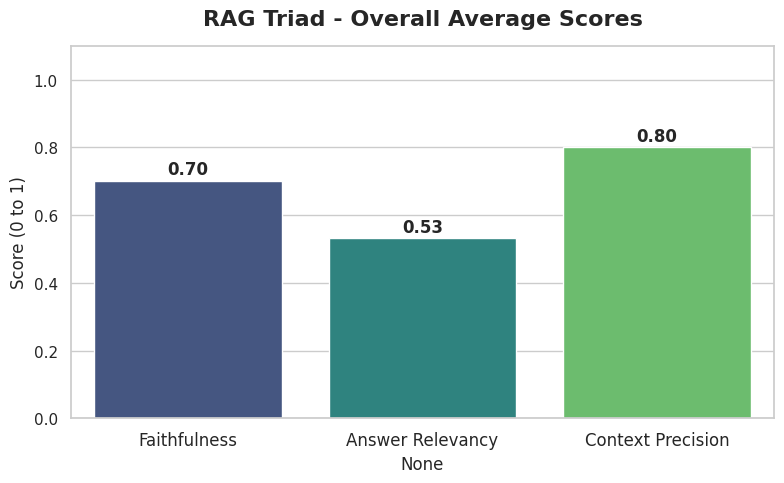

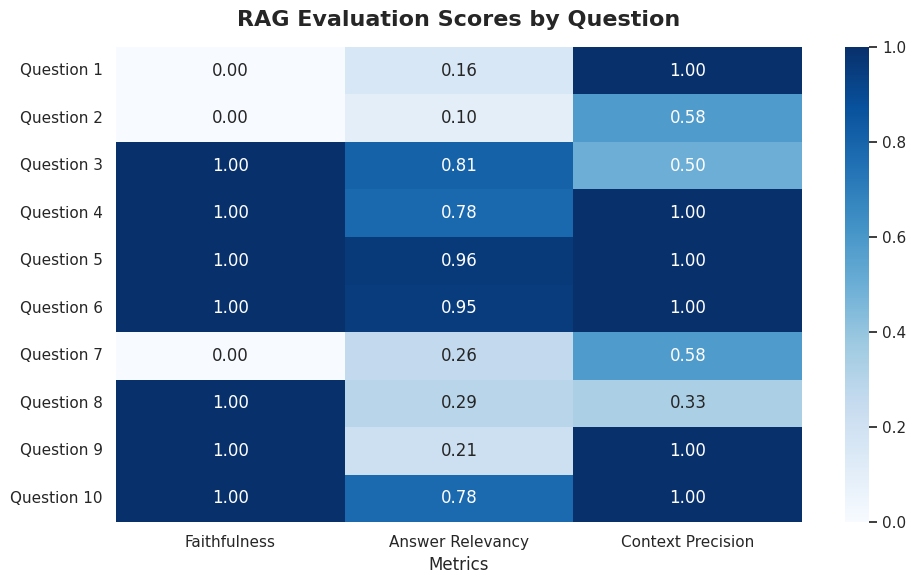

✅ Visualizations generated and saved as 'rag_averages_chart.png' and 'rag_heatmap_chart.png'!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Evaluation Results
df = pd.read_csv("rag_cohere_evaluation_results.csv")
averages = df[['faithfulness', 'answer_relevancy', 'context_precision']].mean()

# Set up the visual style
sns.set_theme(style="whitegrid")

# ==========================================
# CHART 1: Average Scores Bar Chart
# ==========================================
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=averages.index, y=averages.values, palette="viridis")

plt.title('RAG Triad - Overall Average Scores', fontsize=16, fontweight='bold', pad=15)
plt.ylim(0, 1.1) # Set Y-axis from 0 to 1
plt.ylabel('Score (0 to 1)', fontsize=12)
plt.xticks(ticks=[0, 1, 2], labels=['Faithfulness', 'Answer Relevancy', 'Context Precision'], fontsize=12)

# Add the exact numbers on top of the bars
for i, v in enumerate(averages.values):
    ax.text(i, v + 0.02, f"{v:.2f}", ha='center', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig('rag_averages_chart.png', dpi=300) # Saves a high-res image for your Notion/GitHub!
plt.show()

# ==========================================
# CHART 2: Question-by-Question Heatmap
# ==========================================
plt.figure(figsize=(10, 6))
heatmap_data = df[['faithfulness', 'answer_relevancy', 'context_precision']]

sns.heatmap(heatmap_data, annot=True, cmap='Blues', vmin=0, vmax=1, fmt=".2f",
            yticklabels=[f"Question {i+1}" for i in range(len(df))])

plt.title('RAG Evaluation Scores by Question', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Metrics', fontsize=12)
plt.xticks(ticks=[0.5, 1.5, 2.5], labels=['Faithfulness', 'Answer Relevancy', 'Context Precision'])

plt.tight_layout()
plt.savefig('rag_heatmap_chart.png', dpi=300) # Saves a high-res image for your Notion/GitHub!
plt.show()

print("✅ Visualizations generated and saved as 'rag_averages_chart.png' and 'rag_heatmap_chart.png'!")